# **Assignment Enrichment**

**TinyML Hands-on Lab: Gesture Recognition**

Objective:

Simulate a TinyML pipeline: data -> model -> optimization -> inference

# **1. Import Library**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report
np.random.seed(42)

# **2. Function "generate_gesture_data"**

mensimulasikan data accelerometer (X,Y) untuk 4 gestures. Setiap gestures punya "arah dominan" yang berbeda, ditambah noise agar realistis seperti data sensor asli


In [2]:
def generate_gesture_data(labels, samples_per_class=100, noise=0.25):
    """
    Simulasi data accelerometer (X, Y) untuk gesture recognition.

    Parameters
    ----------
    labels : list of str
        Daftar label gesture.
    samples_per_class : int
        Jumlah sampel per kelas.
    noise : float
        Standar deviasi noise sensor.

    Returns
    -------
    X : np.ndarray, shape (n_samples, 2)
        Fitur accelerometer [ax, ay].
    y : np.ndarray, shape (n_samples,)
        Label integer (0..len(labels)-1).
    """
    # Pusat (mean) vektor gerakan untuk tiap gesture:
    #   left  -> akselerasi negatif di X
    #   right -> akselerasi positif di X
    #   up    -> akselerasi positif di Y
    #   down  -> akselerasi negatif di Y
    gesture_centers = {
        'left':  (-0.9,  0.0),
        'right': ( 0.9,  0.0),
        'up':    ( 0.0,  0.9),
        'down':  ( 0.0, -0.9),
    }

    X_list, y_list = [], []
    for idx, label in enumerate(labels):
        cx, cy = gesture_centers[label]
        # Sampling Gaussian di sekitar pusat gerakan + noise sensor
        ax = np.random.normal(cx, noise, samples_per_class)
        ay = np.random.normal(cy, noise, samples_per_class)
        X_list.append(np.column_stack([ax, ay]))
        y_list.append(np.full(samples_per_class, idx))

    X = np.vstack(X_list)
    y = np.concatenate(y_list)

    # Shuffle supaya tidak berurutan per kelas
    perm = np.random.permutation(len(y))
    return X[perm], y[perm]

# **3. Generate data dan Visualisasi dengan label**

Total samples: 400, features: 2
Class distribution: [100 100 100 100]


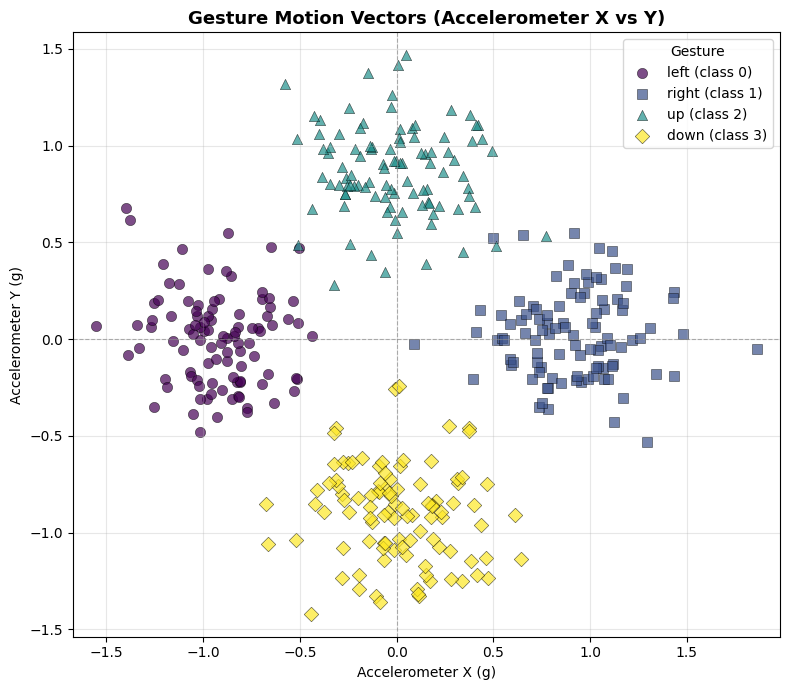

In [3]:
# Step 1: Simulate Gesture Data (Accelerometer X, Y)
labels = ['left', 'right', 'up', 'down']
X, y = generate_gesture_data(labels, samples_per_class=100, noise=0.25)

print(f"Total samples: {X.shape[0]}, features: {X.shape[1]}")
print(f"Class distribution: {np.bincount(y)}")

# Step 2: Visualize Data — dengan label per gesture
plt.figure(figsize=(8, 7))

colors = ['#440154', '#3b528b', '#21918c', '#fde725']  # viridis palette
markers = ['o', 's', '^', 'D']

for idx, label in enumerate(labels):
    mask = (y == idx)
    plt.scatter(
        X[mask, 0], X[mask, 1],
        c=colors[idx], marker=markers[idx],
        label=f"{label} (class {idx})",
        alpha=0.7, edgecolors='k', linewidths=0.4, s=55
    )

# Garis bantu sumbu
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.6)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.6)

plt.title("Gesture Motion Vectors (Accelerometer X vs Y)", fontsize=13, fontweight='bold')
plt.xlabel("Accelerometer X (g)")
plt.ylabel("Accelerometer Y (g)")
plt.legend(title="Gesture", loc='best', frameon=True)
plt.grid(alpha=0.3)
plt.axis('equal')
plt.tight_layout()
plt.show()

# **4. Split dan Scaling**

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f"Train size: {X_train.shape[0]}  |  Test size: {X_test.shape[0]}")

Train size: 320  |  Test size: 80


# **5. Train Decision Tree**

In [5]:
clf_tree = DecisionTreeClassifier(max_depth=3, random_state=42)
clf_tree.fit(X_train_scaled, y_train)

y_pred_tree = clf_tree.predict(X_test_scaled)
acc_tree = accuracy_score(y_test, y_pred_tree)

print(f"[DecisionTree] Test accuracy: {acc_tree:.2%}")
print("\nClassification Report (DecisionTree):")
print(classification_report(y_test, y_pred_tree, target_names=labels))

[DecisionTree] Test accuracy: 90.00%

Classification Report (DecisionTree):
              precision    recall  f1-score   support

        left       0.95      0.95      0.95        20
       right       0.85      0.85      0.85        20
          up       0.86      0.90      0.88        20
        down       0.95      0.90      0.92        20

    accuracy                           0.90        80
   macro avg       0.90      0.90      0.90        80
weighted avg       0.90      0.90      0.90        80



# **6. Train MLP (Neural Network Ringan)**

In [6]:
clf_mlp = MLPClassifier(
    hidden_layer_sizes=(8,),      # kecil -> cocok untuk MCU
    activation='relu',
    solver='adam',
    max_iter=1000,
    random_state=42
)
clf_mlp.fit(X_train_scaled, y_train)

y_pred_mlp = clf_mlp.predict(X_test_scaled)
acc_mlp = accuracy_score(y_test, y_pred_mlp)

print(f"[MLP] Test accuracy: {acc_mlp:.2%}")
print("\nClassification Report (MLP):")
print(classification_report(y_test, y_pred_mlp, target_names=labels))

# Ukuran parameter (proxy untuk footprint TinyML)
n_params = sum(w.size for w in clf_mlp.coefs_) + sum(b.size for b in clf_mlp.intercepts_)
print(f"Total MLP parameters: {n_params} (~{n_params*4} bytes float32, "
      f"~{n_params} bytes int8 setelah quantization)")

[MLP] Test accuracy: 97.50%

Classification Report (MLP):
              precision    recall  f1-score   support

        left       0.95      0.95      0.95        20
       right       1.00      1.00      1.00        20
          up       0.95      0.95      0.95        20
        down       1.00      1.00      1.00        20

    accuracy                           0.97        80
   macro avg       0.97      0.97      0.97        80
weighted avg       0.97      0.97      0.97        80

Total MLP parameters: 60 (~240 bytes float32, ~60 bytes int8 setelah quantization)


# **7. Quantization (int8) - Simulasi TFLite Micro**

In [7]:
def quantize_int8(arr):
    """Simulasi quantization float -> int8 (TFLite Micro style)."""
    arr = np.asarray(arr, dtype=np.float32)
    scale = np.max(np.abs(arr)) / 127.0
    if scale == 0:
        return arr.astype(np.int8), 0.0
    return np.round(arr / scale).astype(np.int8), scale

# Quantize thresholds DecisionTree
thr = clf_tree.tree_.threshold[clf_tree.tree_.threshold != -2]
thr_q, thr_scale = quantize_int8(thr)
print(f"\nDecisionTree thresholds  (float): {np.round(thr[:6], 3)}...")
print(f"DecisionTree thresholds (int8)  : {thr_q[:6]}...")
print(f"Threshold quantization scale    : {thr_scale:.4f}")

# Quantize weights MLP
for i, (W, b) in enumerate(zip(clf_mlp.coefs_, clf_mlp.intercepts_)):
    Wq, sW = quantize_int8(W)
    bq, sb = quantize_int8(b)
    print(f"MLP layer {i+1}: W{W.shape} -> int8 (scale={sW:.4f}), "
          f"b{b.shape} -> int8 (scale={sb:.4f})")


DecisionTree thresholds  (float): [-0.629  1.38  -0.61   1.282  0.516]...
DecisionTree thresholds (int8)  : [-58 127 -56 118  48]...
Threshold quantization scale    : 0.0109
MLP layer 1: W(2, 8) -> int8 (scale=0.0121), b(8,) -> int8 (scale=0.0069)
MLP layer 2: W(8, 4) -> int8 (scale=0.0126), b(4,) -> int8 (scale=0.0059)


# **8. Live Inference Test**

In [8]:
def live_inference(sample_ax, sample_ay, model, name):
    """Simulasi inferensi real-time pada satu sample accelerometer."""
    x = np.array([[sample_ax, sample_ay]])
    x_scaled = scaler.transform(x)
    pred = model.predict(x_scaled)[0]
    proba = model.predict_proba(x_scaled)[0] if hasattr(model, "predict_proba") else None

    print(f"\n[{name}] Input [ax, ay] = [{sample_ax:+.2f}, {sample_ay:+.2f}]")
    print(f"  -> Predicted Gesture : {labels[pred]}")
    if proba is not None:
        conf = {labels[i]: f"{p:.2%}" for i, p in enumerate(proba)}
        print(f"  -> Confidence        : {conf}")

# Test dengan beberapa sample yang meniru gerakan nyata
test_samples = [
    ( 0.12, -0.85),   # dominan ke bawah
    ( 0.88,  0.05),   # dominan ke kanan
    (-0.82,  0.10),   # dominan ke kiri
    ( 0.05,  0.91),   # dominan ke atas
]

for ax, ay in test_samples:
    live_inference(ax, ay, clf_tree, "DecisionTree")

for ax, ay in test_samples:
    live_inference(ax, ay, clf_mlp, "MLP")


[DecisionTree] Input [ax, ay] = [+0.12, -0.85]
  -> Predicted Gesture : down
  -> Confidence        : {'left': '0.00%', 'right': '0.00%', 'up': '0.00%', 'down': '100.00%'}

[DecisionTree] Input [ax, ay] = [+0.88, +0.05]
  -> Predicted Gesture : right
  -> Confidence        : {'left': '0.00%', 'right': '100.00%', 'up': '0.00%', 'down': '0.00%'}

[DecisionTree] Input [ax, ay] = [-0.82, +0.10]
  -> Predicted Gesture : left
  -> Confidence        : {'left': '98.77%', 'right': '0.00%', 'up': '1.23%', 'down': '0.00%'}

[DecisionTree] Input [ax, ay] = [+0.05, +0.91]
  -> Predicted Gesture : up
  -> Confidence        : {'left': '0.00%', 'right': '6.02%', 'up': '93.98%', 'down': '0.00%'}

[MLP] Input [ax, ay] = [+0.12, -0.85]
  -> Predicted Gesture : down
  -> Confidence        : {'left': '0.04%', 'right': '0.90%', 'up': '0.01%', 'down': '99.05%'}

[MLP] Input [ax, ay] = [+0.88, +0.05]
  -> Predicted Gesture : right
  -> Confidence        : {'left': '0.02%', 'right': '98.47%', 'up': '0.46%', '

# **9. Perbandingan Model**



=== Model Comparison ===
Model               Test Acc    Params    
------------------------------------------
DecisionTree        90.00%      11        
MLP (8 hidden)      97.50%      60        


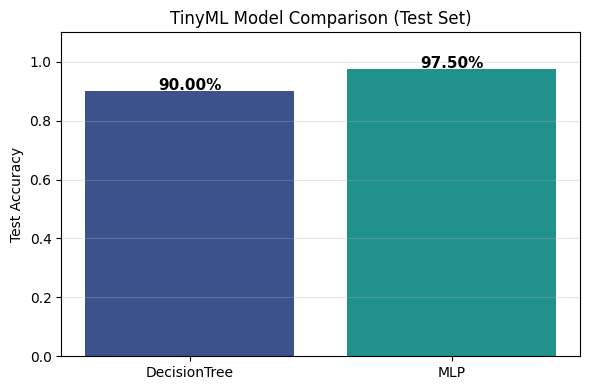

In [9]:
print("\n=== Model Comparison ===")
print(f"{'Model':<20}{'Test Acc':<12}{'Params':<10}")
print("-" * 42)
print(f"{'DecisionTree':<20}{acc_tree:<12.2%}{clf_tree.tree_.node_count:<10}")
print(f"{'MLP (8 hidden)':<20}{acc_mlp:<12.2%}{n_params:<10}")

# Bar chart perbandingan
plt.figure(figsize=(6, 4))
models = ['DecisionTree', 'MLP']
accs   = [acc_tree, acc_mlp]
bars = plt.bar(models, accs, color=['#3b528b', '#21918c'])
for bar, acc in zip(bars, accs):
    plt.text(bar.get_x() + bar.get_width()/2, acc + 0.005,
             f"{acc:.2%}", ha='center', fontsize=11, fontweight='bold')
plt.ylim(0, 1.1)
plt.ylabel("Test Accuracy")
plt.title("TinyML Model Comparison (Test Set)")
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Pada eksperimen ini, MLP dengan 8 hidden neuron mencapai akurasi 97.5% dengan 60 parameter int8 (60 byte), sedangkan Decision Tree depth=3 hanya 90.0% dengan 11 parameter (11 byte). Trade-off ini mengilustrasikan inti TinyML: Decision Tree lebih hemat 5× dalam footprint dan komputasi, tetapi MLP 60-byte masih sangat layak untuk MCU modern (Cortex-M0 punya RAM ≥ 4KB). Untuk aplikasi gesture recognition real-time, pilihan optimal bergantung pada budget energi dan kebutuhan akurasi — keduanya masih di bawah 100 byte sehingga dapat di-flash* bersama firmware utama